In [19]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import griddata

import torch
import torch.autograd as autograd
import torch.nn as nn
import torch.optim as optim

import zipfile
import os

In [20]:
def read_data(filename: str) -> np.ndarray:
    return np.loadtxt(filename)

Размер массива Vx: (40210, 3)
Размер массива Vy: (40210, 3)


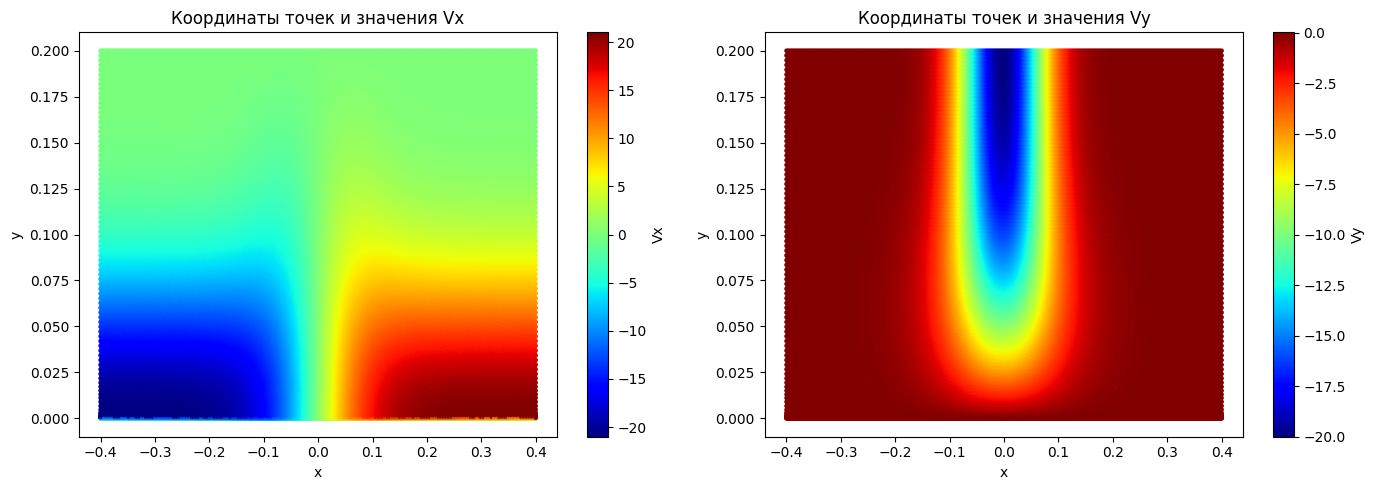

In [21]:
vx_raw = read_data('Vx.txt')
vy_raw = read_data('Vy.txt')

print(f"Размер массива Vx: {vx_raw.shape}")
print(f"Размер массива Vy: {vy_raw.shape}")

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

sc1 = ax[0].scatter(vx_raw[:, 0], vx_raw[:, 1], c=vx_raw[:, 2], cmap='jet', s=5)
plt.colorbar(sc1, ax=ax[0], label='Vx')
ax[0].set_title('Координаты точек и значения Vx')
ax[0].set_xlabel('x')
ax[0].set_ylabel('y')

sc2 = ax[1].scatter(vy_raw[:, 0], vy_raw[:, 1], c=vy_raw[:, 2], cmap='jet', s=5)
plt.colorbar(sc2, ax=ax[1], label='Vy')
ax[1].set_title('Координаты точек и значения Vy')
ax[1].set_xlabel('x')
ax[1].set_ylabel('y')

plt.tight_layout()
plt.show()

In [22]:
class VelocityData:
    def __init__(self, vx, vy):
        self.Vx = vx
        self.Vy = vy

In [23]:
raw_velocity = VelocityData(vx_raw, vy_raw)
print("Экземпляр класса VelocityData создан.")

Экземпляр класса VelocityData создан.


In [24]:
def interpolate_to_uniform_grid(vel_data: VelocityData, nx: int = 10, ny: int = 10):
    x_min, x_max = vel_data.Vx[:, 0].min(), vel_data.Vx[:, 0].max()
    y_min, y_max = vel_data.Vx[:, 1].min(), vel_data.Vx[:, 1].max()

    x_lin = np.linspace(x_min, x_max, nx)
    y_lin = np.linspace(y_min, y_max, ny)
    grid_x, grid_y = np.meshgrid(x_lin, y_lin)

    vx_interp = griddata(vel_data.Vx[:, :2], vel_data.Vx[:, 2], (grid_x, grid_y), method='linear')
    vy_interp = griddata(vel_data.Vy[:, :2], vel_data.Vy[:, 2], (grid_x, grid_y), method='linear')

    if np.isnan(vx_interp).any():
        vx_nearest = griddata(vel_data.Vx[:, :2], vel_data.Vx[:, 2], (grid_x, grid_y), method='nearest')
        vx_interp = np.where(np.isnan(vx_interp), vx_nearest, vx_interp)

    if np.isnan(vy_interp).any():
        vy_nearest = griddata(vel_data.Vy[:, :2], vel_data.Vy[:, 2], (grid_x, grid_y), method='nearest')
        vy_interp = np.where(np.isnan(vy_interp), vy_nearest, vy_interp)

    return grid_x, grid_y, VelocityData(vx_interp, vy_interp)

In [25]:
X_10, Y_10, vel_10 = interpolate_to_uniform_grid(raw_velocity, nx=10, ny=10)

X_100, Y_100, vel_100 = interpolate_to_uniform_grid(raw_velocity, nx=100, ny=100)

print(f"Размерности сетки обучения: X={X_10.shape}, Vx={vel_10.Vx.shape}, Vy={vel_10.Vy.shape}")

Размерности сетки обучения: X=(10, 10), Vx=(10, 10), Vy=(10, 10)


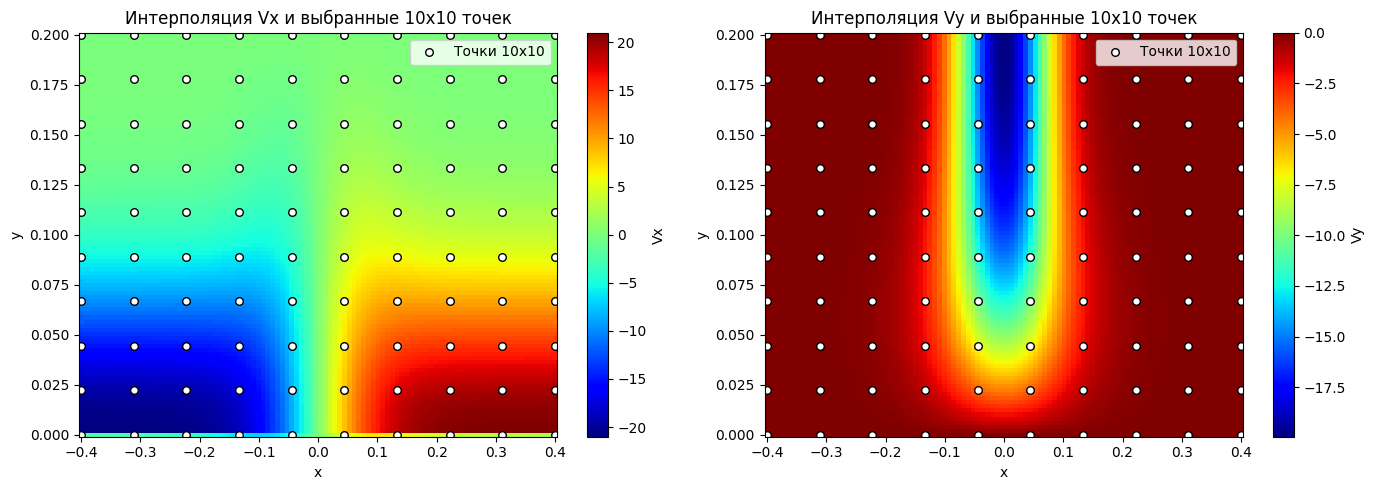

In [26]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

c1 = ax[0].pcolormesh(X_100, Y_100, vel_100.Vx, cmap='jet', shading='auto')
ax[0].scatter(X_10, Y_10, color='white', edgecolor='black', s=30, label='Точки 10x10')
plt.colorbar(c1, ax=ax[0], label='Vx')
ax[0].set_title('Интерполяция Vx и выбранные 10x10 точек')
ax[0].set_xlabel('x')
ax[0].set_ylabel('y')
ax[0].legend()

c2 = ax[1].pcolormesh(X_100, Y_100, vel_100.Vy, cmap='jet', shading='auto')
ax[1].scatter(X_10, Y_10, color='white', edgecolor='black', s=30, label='Точки 10x10')
plt.colorbar(c2, ax=ax[1], label='Vy')
ax[1].set_title('Интерполяция Vy и выбранные 10x10 точек')
ax[1].set_xlabel('x')
ax[1].set_ylabel('y')
ax[1].legend()

plt.tight_layout()
plt.show()

In [27]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Используется устройство: {device}\n")

class NeuralNetwork(nn.Module):
    def __init__(self, hidden_neurons=64):
        super().__init__()
        self.linear_tanh_stack = nn.Sequential(
            nn.Linear(2, hidden_neurons),
            nn.Tanh(),
            nn.Linear(hidden_neurons, hidden_neurons),
            nn.Tanh(),
            nn.Linear(hidden_neurons, hidden_neurons),
            nn.Tanh(),
            nn.Linear(hidden_neurons, 2)
        )

    def forward(self, x):
        return self.linear_tanh_stack(x)


model = NeuralNetwork(hidden_neurons=64).to(device)
print("Архитектура модели:")
print(model)

coords_10x10 = np.vstack((X_10.flatten(), Y_10.flatten())).T
test_input = torch.tensor(coords_10x10, dtype=torch.float32).to(device)

with torch.no_grad():
    test_output = model(test_input)

print(f"\nРазмер входного тензора: {test_input.shape} (100 точек по 2 координаты)")
print(f"Размер выходного тензора: {test_output.shape} (100 предсказаний по 2 компоненты: Vx, Vy)")

Используется устройство: cpu

Архитектура модели:
NeuralNetwork(
  (linear_tanh_stack): Sequential(
    (0): Linear(in_features=2, out_features=64, bias=True)
    (1): Tanh()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): Tanh()
    (4): Linear(in_features=64, out_features=64, bias=True)
    (5): Tanh()
    (6): Linear(in_features=64, out_features=2, bias=True)
  )
)

Размер входного тензора: torch.Size([100, 2]) (100 точек по 2 координаты)
Размер выходного тензора: torch.Size([100, 2]) (100 предсказаний по 2 компоненты: Vx, Vy)


In [28]:
def compute_loss(model, xy_tensor, vx_true, vy_true, weight_div=1.0):
    if not xy_tensor.requires_grad:
        xy_tensor.requires_grad_(True)


    preds = model(xy_tensor)
    vx_pred = preds[:, 0:1]
    vy_pred = preds[:, 1:2]


    grad_vx = torch.autograd.grad(
        vx_pred, xy_tensor,
        grad_outputs=torch.ones_like(vx_pred),
        create_graph=True
    )[0]
    grad_vy = torch.autograd.grad(
        vy_pred, xy_tensor,
        grad_outputs=torch.ones_like(vy_pred),
        create_graph=True
    )[0]

    dvx_dx = grad_vx[:, 0:1]
    dvy_dy = grad_vy[:, 1:2]

    continuity_residual = dvx_dx + dvy_dy
    loss_div = torch.mean(continuity_residual ** 2)


    loss_data = torch.mean((vx_pred - vx_true) ** 2) + torch.mean((vy_pred - vy_true) ** 2)


    total_loss = loss_data + weight_div * loss_div

    return total_loss, loss_data, loss_div

In [29]:

xy_train = torch.tensor(coords_10x10, dtype=torch.float32, requires_grad=True).to(device)
vx_train = torch.tensor(vel_10.Vx.flatten()[:, None], dtype=torch.float32).to(device)
vy_train = torch.tensor(vel_10.Vy.flatten()[:, None], dtype=torch.float32).to(device)


total_loss, l_data, l_div = compute_loss(model, xy_train, vx_train, vy_train)

print(f"Total Loss: {total_loss.item():.6f}")
print(f"  - Data Loss: {l_data.item():.6f}")
print(f"  - Divergence Loss: {l_div.item():.6f}")

Total Loss: 89.276047
  - Data Loss: 89.270020
  - Divergence Loss: 0.006026
